In [2]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr
from matplotlib.projections import PolarAxes

# Loading data

In [3]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

In [4]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [5]:
baseline = 'CurPol_SAP'
folder = '../../Data/Simulations/Overshoots/perturb_around_baseline/'+baseline+'/'
par_files = ['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down']   
ds_D = [xr.open_zarr(folder+par_files[i]+'.zarr') for i in range(6)]
pars = [ds.parameter.to_numpy() for ds in ds_D]
D = [ds.risk.to_numpy() for ds in ds_D]
popt = np.array([float(s.split("= ",1)[1]) for s in [ds_D[1].description.splitlines()[1]] + ds_D[0].description.splitlines()[1:]])

r_data = np.array([critical_parameter(D[i],pars[i],axis=0) for i in range(len(popt))])
#np.array([np.max(np.squeeze(local_safety(D[i]))*pars[i].reshape(len(pars[i]),1),axis=0) for i in range(len(popt))])

# old plotting

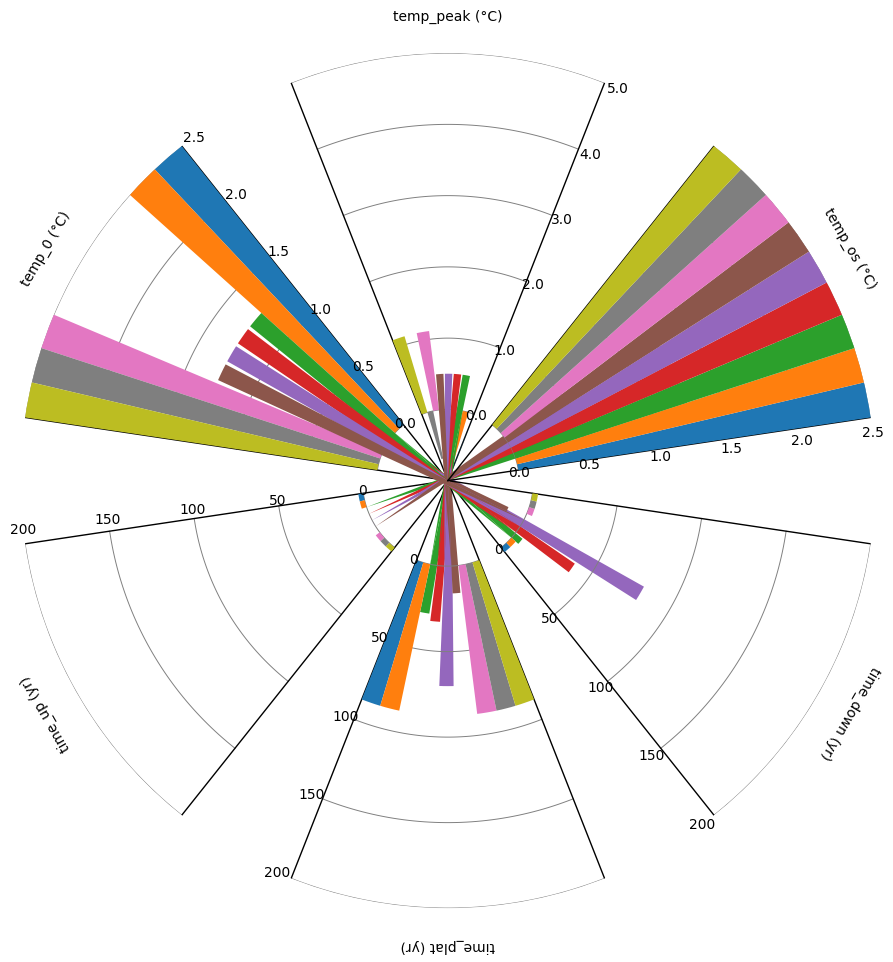

In [6]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,2.5+.1,step=0.5),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,2.5+.1,step=0.5)]
ylims=[(-1,5), (-0.5,2.5), (-50,200), (-50,200), (-50,200), (-0.5,2.5)]
N=r_data.shape[0]
outer_width = 1.1*180/N
inner_width = 180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(9,9))
radar = Radar(fig, titles, rotate_labels=True, wedge_width = width, with_rlabels=True, ylims=ylims, rticks=rticks)

sim2ax_reorder = [1,0,3,4,5,2]
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
for i in range(r_data.shape[1]):
    angles = np.array(radar.angles) + width*(i/r_data.shape[1] - 1/2 + 1/r_data.shape[1]/2)
    radar.bar(popt-r_data[sim2ax_reorder,i],
              color=colors[i],
              width=np.deg2rad(width/r_data.shape[1]), 
              angles=np.deg2rad(angles))
# radar.bar(popt[sim2ax_reorder],color='r',width=np.deg2rad(inner_width))

# best plots

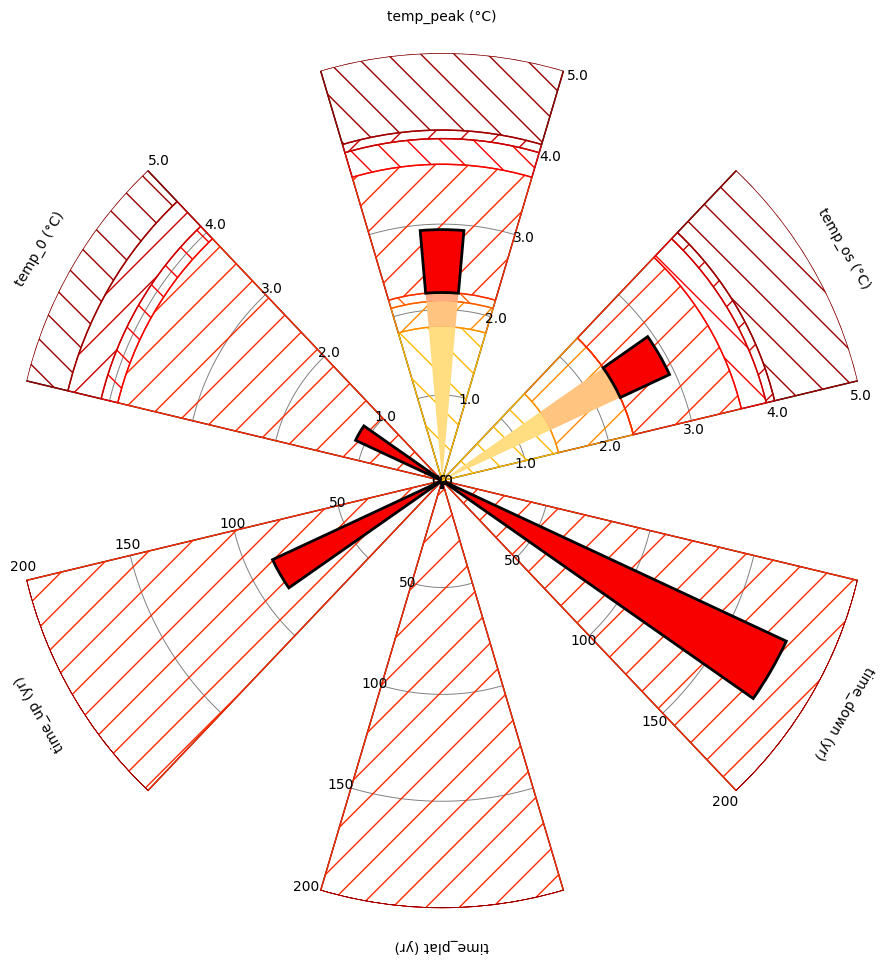

In [257]:
titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=r_data.shape[0]
outer_width = 1.1*180/N
inner_width = 180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(9,9))
radar = Radar(fig, titles, rotate_labels=True, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks)

sim2ax_reorder = [1,0,3,4,5,2]
colors_g = mpl.colormaps['Greens_r'](np.linspace(0, 1, 15))
colors_h = mpl.colormaps['hot_r'](np.linspace(0, 1, 15))
r_noreef = np.delete(r_data, 6, axis=1)
r_sort=np.sort(r_noreef,axis=1)
no_breached = np.sum(popt.reshape(r_sort.shape[0],1) > r_sort,axis=1)
nb = no_breached[0]
hatches=['/','\\'] 

for j, ax, angle in zip(range(r_sort.shape[0]), radar.axes, radar.angles):
    r_plot = r_sort[sim2ax_reorder,:][j,:]
    angle_rad = np.deg2rad(angle)
    
    # plotting hatched boxes first, i.e. the potential ones
    bottom = 0
    ax.bar(np.deg2rad(angle),r_plot[0],color='none',
           edgecolor='green',hatch=hatches[0],alpha=1, 
           width=np.deg2rad(outer_width),bottom=bottom)
    bottom=max(bottom,r_plot[0])
    for i,r in enumerate(r_plot[1:]):
        ax.bar(np.deg2rad(angle), r-bottom, 
               color='none', hatch=hatches[(i+1)%2],
               edgecolor=colors_h[5+i],alpha=1,
               width = np.deg2rad(outer_width),
               bottom=bottom)
        bottom=max(bottom,r)

    # plotting full boxes up until the current parameter value
    bottom = 0
    r_green = min(r_plot[0], popt[sim2ax_reorder][j])
    ax.bar(np.deg2rad(angle), r_green,
           color='g', width=np.deg2rad(inner_width))
    bottom = max(bottom,r_green)
    for i,r in enumerate(r_plot[1:nb]):
        ax.bar(np.deg2rad(angle), r-bottom, 
               color=lighten_color(colors_h[5+i]),
               width = np.deg2rad(inner_width),
               bottom=bottom)
        bottom = max(bottom,r)
    ax.bar(np.deg2rad(angle), popt[sim2ax_reorder][j]-bottom,
           color=colors_h[5+nb], width=np.deg2rad(inner_width),
           bottom=bottom,edgecolor='k',lw=2)
    # ax.plot(np.linspace(angle_rad-np.deg2rad(inner_width/2), 
    #                     angle_rad+np.deg2rad(inner_width/2)),
    #         [popt[sim2ax_reorder][j]]*50,c='k',lw=2)
    # bottoms = r_plot[j,:].max()*np.ones(r_sort.shape[1]-nb+1)
    # bottom = popt[sim2ax_reorder][j]
    # ax.bar(np.deg2rad(angle), r_plot[j,0]-r_green,
    #        color='g', width=np.deg2rad(outer_width),bottom=r_green,hatch='/')
    # for i,r in enumerate(r_sort[sim2ax_reorder,:][j,nb+1:]):
    #     if np.any(bottoms<r):
    #         bottom = bottoms[bottoms<r][-1]
    #     else:
    #         bottom = popt[sim2ax_reorder][j]
    #     ax.bar(np.deg2rad(angle), r-bottom, 
    #            color=colors_h[2+i],
    #            width = np.deg2rad(outer_width),
    #            bottom=bottom)
    #     bottoms[i+1]=r
folder='../../Figures/Overshoots/perturb_around_baseline/'
# fig.savefig(folder+'SOS_%s.png'%baseline,bbox_inches='tight')